# 07 · Model Building & Validation
Module 3.1 (Model validation)

We train **seven classifiers** to predict heart disease and check how well they work with four validation strategies:

| Strategy | How it works | Why use it |
|---|---|---|
| **Hold-out (80/20)** | train on 80% of patients, test once on the other 20% | simple baseline, but depends on *which* patients land in the test set |
| **Stratified 5-fold CV** | split into 5 parts; each part is the test set once | every patient is tested once; gives mean ± std |
| **Stratified 10-fold CV** | same with 10 parts | more training data per fold, more stable estimate |
| **Leave-One-Out CV** | n folds, each tests a single patient | almost all data used for training; very expensive |

Plus **bootstrapping** to put a 95% confidence interval on the best model's recall, and **GridSearchCV** hyper-parameter tuning.
*Stratified* means every fold keeps the same 55/45 ratio of sick/healthy patients as the full dataset.

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)
import time, joblib, platform
import sklearn, xgboost, scipy
from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from src import models as M
set_config(display="text")

## 1. Load the data
We load the **raw** data. All cleaning (zeros → missing, imputation, scaling, one-hot encoding) happens **inside** the pipeline.

In [2]:
df = data.load_raw()
X, y = M.split_xy(df)
print("X:", X.shape, " y:", y.shape, " positive rate:", f"{y.mean():.1%}")

X: (918, 11)  y: (918,)  positive rate: 55.3%


## 1b. Class imbalance and SMOTE
A dataset is **imbalanced** when one class is much rarer than the other (e.g. 95% healthy, 5% sick). Models then tend to
predict the majority class and miss the minority. Let us measure our balance:

In [3]:
counts = y.value_counts().sort_index()
print(f"No heart disease: {counts[0]}  |  Heart disease: {counts[1]}  |  ratio = {counts[1] / counts[0]:.2f} : 1")

No heart disease: 410  |  Heart disease: 508  |  ratio = 1.24 : 1


**SMOTE (Synthetic Minority Over-sampling TEchnique)** is the standard fix for strong imbalance. Instead of copying minority
rows, it **creates new synthetic patients**:
1. pick a minority-class patient *A*;
2. find its *k* nearest minority-class neighbours and pick one, *B*;
3. create a new point on the straight line between them: $x_{new} = A + \lambda\,(B - A)$ with a random λ between 0 and 1.

Repeat until both classes are equally large. The small demo below does exactly this by hand on two features (Age, MaxHR)
for the smaller class (no heart disease), just to visualise the idea:

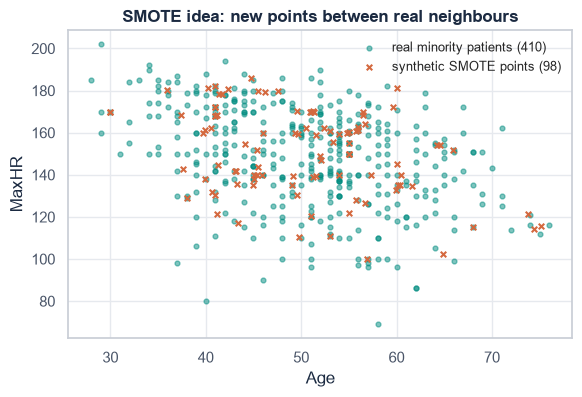

In [4]:
from sklearn.neighbors import NearestNeighbors

def smote_demo(points, n_new, k=5, random_state=C.RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    nn = NearestNeighbors(n_neighbors=k + 1).fit(points)
    _, idx = nn.kneighbors(points)                 # idx[:, 0] is the point itself
    new = []
    for _ in range(n_new):
        a = rng.integers(len(points))
        b = idx[a, rng.integers(1, k + 1)]
        lam = rng.random()
        new.append(points[a] + lam * (points[b] - points[a]))
    return np.array(new)

minority = df.loc[y == 0, ["Age", "MaxHR"]].to_numpy(dtype=float)
synthetic = smote_demo(minority, n_new=counts[1] - counts[0])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(minority[:, 0], minority[:, 1], s=12, color=C.TEAL, alpha=0.5, label=f"real minority patients ({len(minority)})")
ax.scatter(synthetic[:, 0], synthetic[:, 1], s=16, color=C.CLASS_COLORS[1], marker="x",
           label=f"synthetic SMOTE points ({len(synthetic)})")
ax.set_xlabel("Age")
ax.set_ylabel("MaxHR")
ax.set_title("SMOTE idea: new points between real neighbours")
ax.legend(frameon=False, fontsize=9)
plots.save_fig(fig, "07_smote_demo")
plt.show()

**Why we do NOT apply SMOTE to our models:**
* Our classes are only mildly imbalanced (1.24 : 1). Stratified splitting keeps this ratio in every fold, and the models
  already reach recall ≈ 0.9 - there is no minority class being ignored.
* Here the *smaller* class is the **healthy** group. Over-sampling it would push the models towards predicting "healthy",
  which would **lower recall** - the opposite of what we want in screening.
* If SMOTE were needed, it must be applied **only to the training folds** (e.g. inside an `imblearn` Pipeline), never before the
  split, otherwise synthetic copies of test patients leak into training.

## 2. The pipeline - and why it prevents data leakage
**Data leakage** happens when information from the test data sneaks into training. Example: if we compute the median cholesterol or
the scaling mean on *all* 918 patients and *then* split, the test patients have already influenced the preprocessing, and the scores
are too optimistic.

A sklearn **Pipeline** bundles preprocessing and the model into one object. When we call `fit()` on the training data, the imputer
learns its median and the scaler learns its mean/std **only from the training data**; on the test data they only `transform()`.
Every CV fold re-fits the whole pipeline, so leakage is impossible.

Our pipeline:
1. `Cholesterol`, `RestingBP`: zeros → NaN → median imputer → standard scaler
2. `Age`, `MaxHR`, `Oldpeak`: median imputer → standard scaler
3. Categorical features: most-frequent imputer → one-hot encoder
4. The classifier

In [5]:
M.make_pipeline(M.get_models()["Logistic Regression"])

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('zero_num',
                                                  Pipeline(steps=[('zero_to_nan',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function zero_to_nan at 0x000002A0696516C0>)),
                                                                  ('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['Cholesterol', 'RestingBP']),
                                                 ('num',
                                                  Pipeline(steps=[('impute',
              

## 3. The seven models
| Model | Idea in one line |
|---|---|
| Logistic Regression | weighted sum of features passed through a sigmoid to give a probability |
| KNN (k = 11) | look at the 11 most similar patients and take a majority vote |
| Decision Tree (depth 4) | a flowchart of yes/no questions on the features |
| Random Forest (300 trees) | many decision trees on random subsets of data/features; average their votes |
| SVM (RBF kernel) | finds the boundary with the widest margin between the classes (in a transformed space) |
| Gaussian Naive Bayes | Bayes' theorem assuming features are independent and normally distributed |
| XGBoost | trees built one after another, each correcting the errors of the previous ones (gradient boosting) |

All models that involve randomness use `random_state=42`.

In [6]:
models = M.get_models()
for name, m in models.items():
    print(f"{name:22s} {m}")

Logistic Regression    LogisticRegression(max_iter=1000, random_state=42)
KNN                    KNeighborsClassifier(n_neighbors=11)
Decision Tree          DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=42)
Random Forest          RandomForestClassifier(min_samples_leaf=2, n_estimators=300, n_jobs=-1,
                       random_state=42)
SVM                    SVC(probability=True, random_state=42)
Gaussian Naive Bayes   GaussianNB()
XGBoost                XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_one

## 4. Baseline: single stratified 80/20 hold-out split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=C.RANDOM_STATE)
print(f"Train: {len(X_train)} patients ({y_train.mean():.1%} positive) | Test: {len(X_test)} patients ({y_test.mean():.1%} positive)")

holdout, holdout_prob, fitted = {}, {}, {}
for name, model in models.items():
    pipe = M.make_pipeline(model)
    metrics, pred, prob = M.holdout_evaluate(pipe, X_train, X_test, y_train, y_test)
    holdout[name], holdout_prob[name], fitted[name] = metrics, prob, pipe

holdout_df = pd.DataFrame(holdout).T[["accuracy", "precision", "recall", "f1", "roc_auc", "specificity", "fp", "fn"]]
holdout_df[["fp", "fn"]] = holdout_df[["fp", "fn"]].astype(int)
holdout_df.sort_values("recall", ascending=False).round(3)

Train: 734 patients (55.3% positive) | Test: 184 patients (55.4% positive)


,accuracy,precision,recall,f1,roc_auc,specificity,fp,fn
Random Forest,0.897,0.888,0.931,0.909,0.931,0.854,12,7
Logistic Regression,0.886,0.886,0.912,0.899,0.933,0.854,12,9
SVM,0.870,0.868,0.902,0.885,0.941,0.829,14,10
KNN,0.886,0.901,0.892,0.897,0.942,0.878,10,11
Gaussian Naive Bayes,0.864,0.874,0.882,0.878,0.909,0.841,13,12
XGBoost,0.875,0.899,0.873,0.886,0.921,0.878,10,13
Decision Tree,0.793,0.820,0.804,0.812,0.848,0.780,18,20


A single split is quick, but the scores depend on which 184 patients happened to be in the test set. Cross-validation fixes this.

## 5. Stratified 5-fold and 10-fold cross-validation
For each model we report the **mean ± standard deviation** across the folds of accuracy, precision, recall, F1 and ROC-AUC.
The standard deviation shows how *stable* the model is.

In [8]:
cv_results = {}
for k in [5, 10]:
    t0 = time.time()
    cv_results[k] = {name: M.kfold_evaluate(M.make_pipeline(m), X, y, n_splits=k) for name, m in models.items()}
    print(f"{k}-fold CV for 7 models took {time.time() - t0:.1f} s")

def pm_table(res):
    return pd.DataFrame({name: {M.METRIC_NAMES[m]: f"{v[0]:.3f} ± {v[1]:.3f}" for m, v in scores.items()}
                         for name, scores in res.items()}).T

display(Markdown("**Stratified 5-fold CV (mean ± std)**"))
display(pm_table(cv_results[5]))
display(Markdown("**Stratified 10-fold CV (mean ± std)**"))
display(pm_table(cv_results[10]))

5-fold CV for 7 models took 3.8 s


10-fold CV for 7 models took 7.6 s


**Stratified 5-fold CV (mean ± std)**

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.861 ± 0.021,0.865 ± 0.030,0.888 ± 0.040,0.876 ± 0.019,0.921 ± 0.020
KNN,0.857 ± 0.021,0.857 ± 0.037,0.894 ± 0.033,0.874 ± 0.018,0.910 ± 0.022
Decision Tree,0.821 ± 0.013,0.829 ± 0.017,0.854 ± 0.024,0.841 ± 0.012,0.899 ± 0.015
Random Forest,0.865 ± 0.035,0.862 ± 0.044,0.904 ± 0.032,0.881 ± 0.029,0.925 ± 0.026
SVM,0.865 ± 0.029,0.856 ± 0.038,0.912 ± 0.025,0.882 ± 0.024,0.920 ± 0.021
Gaussian Naive Bayes,0.855 ± 0.018,0.874 ± 0.033,0.864 ± 0.024,0.869 ± 0.014,0.914 ± 0.016
XGBoost,0.865 ± 0.023,0.867 ± 0.041,0.896 ± 0.019,0.881 ± 0.017,0.923 ± 0.025


**Stratified 10-fold CV (mean ± std)**

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.862 ± 0.032,0.866 ± 0.040,0.890 ± 0.045,0.877 ± 0.029,0.920 ± 0.031
KNN,0.858 ± 0.030,0.856 ± 0.041,0.898 ± 0.047,0.875 ± 0.027,0.914 ± 0.036
Decision Tree,0.834 ± 0.027,0.834 ± 0.034,0.878 ± 0.059,0.854 ± 0.026,0.901 ± 0.030
Random Forest,0.868 ± 0.037,0.865 ± 0.046,0.906 ± 0.044,0.884 ± 0.032,0.928 ± 0.030
SVM,0.869 ± 0.034,0.864 ± 0.045,0.910 ± 0.046,0.885 ± 0.030,0.924 ± 0.031
Gaussian Naive Bayes,0.856 ± 0.033,0.875 ± 0.042,0.866 ± 0.046,0.869 ± 0.031,0.913 ± 0.027
XGBoost,0.868 ± 0.030,0.869 ± 0.041,0.900 ± 0.042,0.883 ± 0.026,0.926 ± 0.030


## 6. Leave-One-Out CV (Logistic Regression and Naive Bayes only)
LOOCV trains the model **n = 918 times**, each time leaving out exactly one patient and testing on it. Because a single patient
cannot have a precision or recall, we collect all 918 out-of-sample predictions and compute the metrics once at the end.

**Why only LR and Naive Bayes?** They train in milliseconds. The others are far more expensive: Random Forest builds 300 trees per fit,
XGBoost 300 boosting rounds, and SVM with `probability=True` runs an extra internal 5-fold CV for every fit - so 918 fits would take
many minutes for little benefit, because 10-fold CV already gives a reliable estimate. We time one fit of each model to show this:

In [9]:
fit_times = {}
for name, m in models.items():
    t0 = time.time()
    M.make_pipeline(m).fit(X_train, y_train)
    fit_times[name] = time.time() - t0
pd.DataFrame({"One fit (s)": fit_times,
              "Estimated LOOCV time (s, 918 fits, 1 core)": {k: v * len(X) for k, v in fit_times.items()}}).round(3)

,One fit (s),"Estimated LOOCV time (s, 918 fits, 1 core)"
Logistic Regression,0.015,13.494
KNN,0.011,10.087
Decision Tree,0.012,11.193
Random Forest,0.338,310.143
SVM,0.050,45.596
Gaussian Naive Bayes,0.012,11.109
XGBoost,0.058,53.696


LR and Naive Bayes are cheap enough, so we now run the real LOOCV for these two models (918 fits each):

In [10]:
loocv = {}
for name in ["Logistic Regression", "Gaussian Naive Bayes"]:
    t0 = time.time()
    loocv[name] = M.loocv_evaluate(M.make_pipeline(models[name]), X, y)
    print(f"LOOCV {name}: {time.time() - t0:.1f} s for {len(X)} fits")
pd.DataFrame({n: {M.METRIC_NAMES[m]: v[0] for m, v in s.items()} for n, s in loocv.items()}).T.round(3)

LOOCV Logistic Regression: 20.7 s for 918 fits


LOOCV Gaussian Naive Bayes: 18.0 s for 918 fits


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.857,0.863,0.882,0.872,0.922
Gaussian Naive Bayes,0.855,0.873,0.864,0.868,0.912


## 7. Comparison across validation strategies
We gather every result into one long table (model × strategy × metric).

In [11]:
rows = []
for name in models:
    for m in M.SCORING:
        rows.append({"model": name, "strategy": "Hold-out 80/20", "metric": m, "mean": holdout[name][m], "std": None})
        rows.append({"model": name, "strategy": "5-fold CV", "metric": m, "mean": cv_results[5][name][m][0], "std": cv_results[5][name][m][1]})
        rows.append({"model": name, "strategy": "10-fold CV", "metric": m, "mean": cv_results[10][name][m][0], "std": cv_results[10][name][m][1]})
        if name in loocv:
            rows.append({"model": name, "strategy": "LOOCV", "metric": m, "mean": loocv[name][m][0], "std": None})
results = pd.DataFrame(rows)
strategies = ["Hold-out 80/20", "5-fold CV", "10-fold CV", "LOOCV"]

for metric in ["recall", "f1"]:
    display(Markdown(f"**{M.METRIC_NAMES[metric]} by model and validation strategy**"))
    display(results[results.metric == metric].pivot(index="model", columns="strategy", values="mean")[strategies].round(3))

**Recall by model and validation strategy**

strategy,Hold-out 80/20,5-fold CV,10-fold CV,LOOCV
model,,,,
Decision Tree,0.804,0.854,0.878,NaN
Gaussian Naive Bayes,0.882,0.864,0.866,0.864
KNN,0.892,0.894,0.898,NaN
Logistic Regression,0.912,0.888,0.890,0.882
Random Forest,0.931,0.904,0.906,NaN
SVM,0.902,0.912,0.910,NaN
XGBoost,0.873,0.896,0.900,NaN


**F1 by model and validation strategy**

strategy,Hold-out 80/20,5-fold CV,10-fold CV,LOOCV
model,,,,
Decision Tree,0.812,0.841,0.854,NaN
Gaussian Naive Bayes,0.878,0.869,0.869,0.868
KNN,0.897,0.874,0.875,NaN
Logistic Regression,0.899,0.876,0.877,0.872
Random Forest,0.909,0.881,0.884,NaN
SVM,0.885,0.882,0.885,NaN
XGBoost,0.886,0.881,0.883,NaN


Grouped bar chart: each model has one bar per validation strategy (LOOCV only for LR and Naive Bayes).

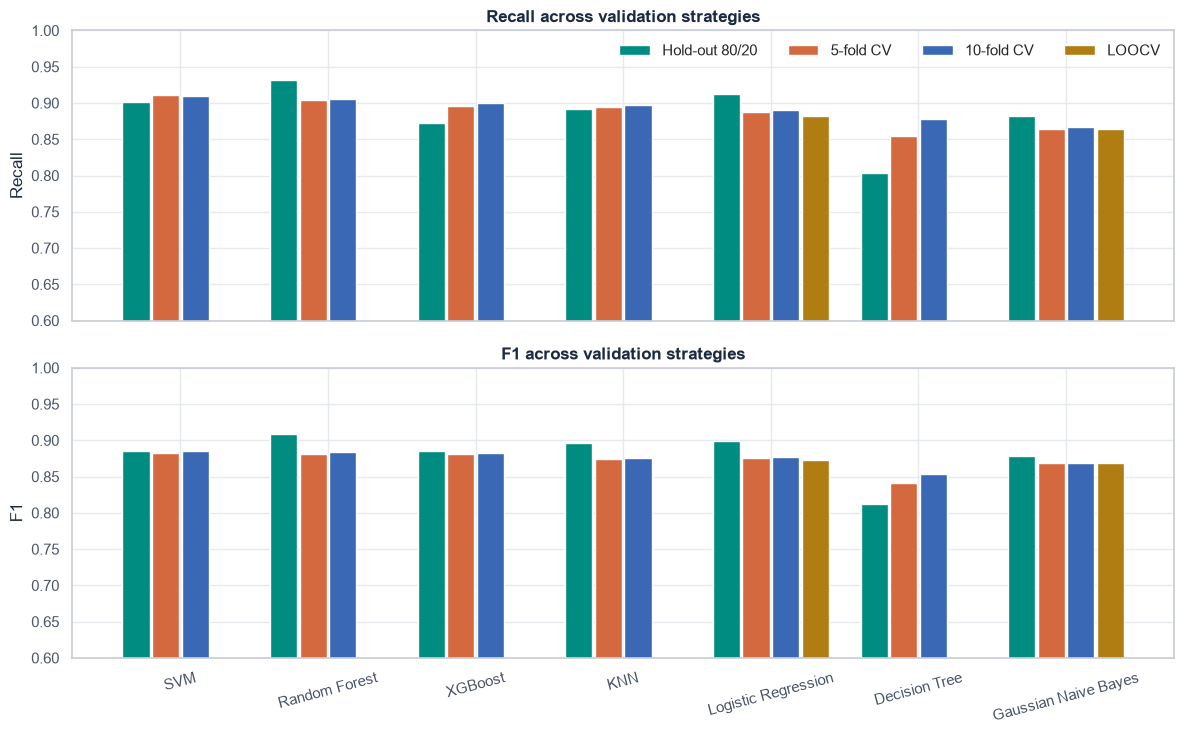

In [12]:
order = results[(results.metric == "recall") & (results.strategy == "10-fold CV")].sort_values("mean", ascending=False)["model"].tolist()
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
width = 0.2
for ax, metric in zip(axes, ["recall", "f1"]):
    piv = results[results.metric == metric].pivot(index="model", columns="strategy", values="mean").reindex(order)
    for i, strat in enumerate(strategies):
        xs = np.arange(len(order)) + (i - 1.5) * width
        ax.bar(xs, piv[strat], width=width * 0.92, color=C.PALETTE_LIGHT[i], label=strat)
    ax.set_ylim(0.6, 1.0)
    ax.set_ylabel(M.METRIC_NAMES[metric])
    ax.set_title(f"{M.METRIC_NAMES[metric]} across validation strategies")
axes[1].set_xticks(np.arange(len(order)), order, rotation=15)
axes[0].legend(ncol=4, frameon=False, loc="upper right")
fig.tight_layout()
plots.save_fig(fig, "07_validation_comparison")
plt.show()

## 8. Selecting the final model
**Rule:** rank the models by the **average of recall and F1 under stratified 10-fold CV**.
* **Recall** comes first in importance because a missed patient (false negative, Type II error) is the dangerous mistake.
* But recall alone can be gamed - a model that says "disease" for everyone has 100% recall. Including **F1** (which also contains
  precision) makes sure the model does not flood doctors with false alarms.
* We use **10-fold CV** rather than the single hold-out split because it tests every patient once and averages over 10 different splits,
  so it is less affected by luck.

In [13]:
cv10 = results[results.strategy == "10-fold CV"].pivot(index="model", columns="metric", values="mean")
ranking = cv10[["recall", "f1", "precision", "accuracy", "roc_auc"]].copy()
ranking["selection score = (recall + F1) / 2"] = (ranking["recall"] + ranking["f1"]) / 2
ranking = ranking.sort_values("selection score = (recall + F1) / 2", ascending=False)
best_name = ranking.index[0]
display(ranking.round(4))
display(Markdown(f"### Selected model: **{best_name}**"))

metric,recall,f1,precision,accuracy,roc_auc,selection score = (recall + F1) / 2
model,,,,,,
SVM,0.910,0.885,0.864,0.869,0.924,0.897
Random Forest,0.906,0.884,0.865,0.868,0.928,0.895
XGBoost,0.900,0.883,0.869,0.868,0.926,0.891
KNN,0.898,0.875,0.856,0.858,0.914,0.886
Logistic Regression,0.890,0.877,0.866,0.862,0.920,0.883
Gaussian Naive Bayes,0.866,0.869,0.875,0.856,0.913,0.868
Decision Tree,0.878,0.854,0.834,0.834,0.901,0.866


### Selected model: **SVM**

## 8b. A note on optimisation
**Training a model = solving an optimisation problem**: find the parameters that minimise a loss (error) on the training data.
* **Logistic Regression** minimises the *log-loss* with an iterative gradient-based solver (L-BFGS), plus an L2 penalty that keeps weights small.
* **SVM** solves a *quadratic optimisation* problem: maximise the margin between the classes while penalising misclassified points (strength set by **C**).
* **Decision Tree / Random Forest** use a *greedy* search: at each node choose the split that reduces Gini impurity the most.
* **XGBoost** performs *gradient boosting*: each new tree is fitted to the gradient of the loss, like gradient descent in "function space".
* **KNN** and **Naive Bayes** do almost no optimisation - KNN stores the data; Naive Bayes just estimates means and variances.

The settings we choose **before** training (C, γ, tree depth, k, ...) are **hyper-parameters**. Choosing them is a second,
outer optimisation problem: **hyper-parameter tuning**.

## 8c. Hyper-parameter tuning with GridSearchCV
`GridSearchCV` tries **every combination** in a grid of hyper-parameters and scores each with stratified 5-fold CV.
To keep the test set untouched, the search runs **only on the 80% training split**. We tune the selected model with the same
selection score, (recall + F1) / 2. For the SVM: **C** (penalty for misclassification - small C = smoother boundary) and
**γ** (how far one training point's influence reaches - large γ = more wiggly boundary).

In [14]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
grid = M.PARAM_GRIDS[best_name]
search = GridSearchCV(M.make_pipeline(M.get_models()[best_name]), grid, scoring=M.SELECTION_SCORER,
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=C.RANDOM_STATE))
t0 = time.time()
search.fit(X_train, y_train)
n_combos = len(search.cv_results_["params"])
print(f"Tried {n_combos} combinations x 5 folds = {n_combos * 5} fits in {time.time() - t0:.1f} s")

cvres = pd.DataFrame(search.cv_results_)
param_cols = [c for c in cvres.columns if c.startswith("param_")]
top = cvres.sort_values("rank_test_score")[param_cols + ["mean_test_score", "std_test_score"]].head(8)
top.columns = [c.replace("param_model__", "") for c in top.columns]
top.round(4)

Tried 24 combinations x 5 folds = 120 fits in 6.3 s


,C,gamma,mean_test_score,std_test_score
7,0.500,0.100,0.892,0.021
4,0.500,scale,0.889,0.019
6,0.500,0.030,0.889,0.022
10,1.000,0.030,0.888,0.025
0,0.100,scale,0.887,0.028
11,1.000,0.100,0.887,0.020
8,1.000,scale,0.886,0.020
3,0.100,0.100,0.886,0.028


For the SVM we can draw the whole grid as a heatmap (rows = C, columns = γ):

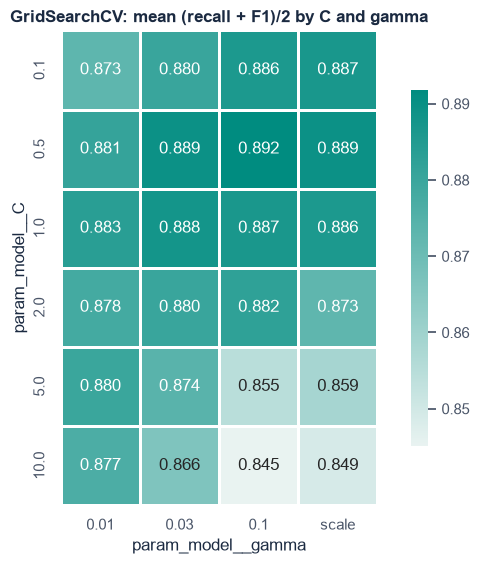

In [15]:
if best_name == "SVM":
    heat = cvres.pivot_table(index="param_model__C", columns=cvres["param_model__gamma"].astype(str),
                             values="mean_test_score")
    fig = plots.corr_heatmap(heat, "GridSearchCV: mean (recall + F1)/2 by C and gamma", fmt=".3f", center=None,
                             cmap=sns.light_palette(C.TEAL, as_cmap=True))
    plots.save_fig(fig, "07_gridsearch_heatmap")
    plt.show()
else:
    print("Heatmap is only drawn for the SVM grid.")

**Should we use the tuned settings?** We compare the best grid combination with the default settings *on the same CV folds*.
A gain smaller than the fold-to-fold standard deviation is just noise - adopting it would be **over-fitting to the validation
folds**. So the rule is: adopt the tuned hyper-parameters only if the gain is larger than one standard deviation.

In [16]:
defaults = M.get_models()[best_name].get_params()
default_key = {k: defaults[k.replace("model__", "")] for k in grid}
is_default = cvres["params"].apply(lambda prm: all(prm[k] == v for k, v in default_key.items()))
default_score = float(cvres.loc[is_default, "mean_test_score"].iloc[0]) if is_default.any() else float("nan")
best_score, best_std = float(search.best_score_), float(cvres.loc[search.best_index_, "std_test_score"])
gain = best_score - default_score
use_tuned = bool(gain > best_std)

print(f"Default settings {default_key}: CV score = {default_score:.4f}")
print(f"Best grid settings {search.best_params_}: CV score = {best_score:.4f} (std {best_std:.4f})")
print(f"Gain = {gain:+.4f}  ->  {'ADOPT tuned settings' if use_tuned else 'KEEP default settings (gain is within noise)'}")

if use_tuned:   # replace the selected model by the tuned pipeline (already re-fitted on the training split)
    fitted[best_name] = search.best_estimator_
    holdout[best_name], _, holdout_prob[best_name] = M.holdout_evaluate(search.best_estimator_, X_train, X_test,
                                                                        y_train, y_test)

tuning = {"model": best_name, "grid": {k: [str(v) for v in vals] for k, vals in grid.items()},
          "n_combinations": n_combos, "best_params": {k: str(v) for k, v in search.best_params_.items()},
          "best_cv_score": best_score, "best_cv_std": best_std, "default_cv_score": default_score,
          "gain": gain, "used_tuned": use_tuned}

Default settings {'model__C': 1.0, 'model__gamma': 'scale'}: CV score = 0.8860
Best grid settings {'model__C': 0.5, 'model__gamma': 0.1}: CV score = 0.8918 (std 0.0213)
Gain = +0.0058  ->  KEEP default settings (gain is within noise)


## 9. Best model on the hold-out test set
### 9.1 Confusion matrix

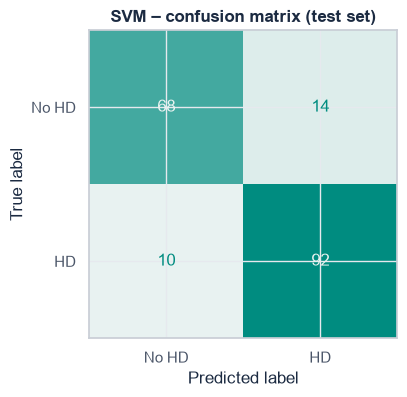

True negatives :  68  healthy patients correctly cleared
True positives :  92  sick patients correctly flagged
False positives:  14  TYPE I errors  – healthy people told they may have heart disease (extra tests, anxiety)
False negatives:  10  TYPE II errors – sick patients MISSED (the dangerous error)

Recall (sensitivity) = TP/(TP+FN) = 0.902  -> catches 90.2% of sick patients
Specificity          = TN/(TN+FP) = 0.829
Precision            = TP/(TP+FP) = 0.868


In [17]:
best_pipe = fitted[best_name]
best_prob = holdout_prob[best_name]
best_pred = (best_prob >= 0.5).astype(int)
bm = holdout[best_name]

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["No HD", "HD"],
                                        cmap=sns.light_palette(C.TEAL, as_cmap=True), colorbar=False, ax=ax)
ax.set_title(f"{best_name} – confusion matrix (test set)")
plots.save_fig(fig, "07_confusion_matrix")
plt.show()

print(f"True negatives : {bm['tn']:3d}  healthy patients correctly cleared")
print(f"True positives : {bm['tp']:3d}  sick patients correctly flagged")
print(f"False positives: {bm['fp']:3d}  TYPE I errors  – healthy people told they may have heart disease (extra tests, anxiety)")
print(f"False negatives: {bm['fn']:3d}  TYPE II errors – sick patients MISSED (the dangerous error)")
print(f"\nRecall (sensitivity) = TP/(TP+FN) = {bm['recall']:.3f}  -> catches {bm['recall']:.1%} of sick patients")
print(f"Specificity          = TN/(TN+FP) = {bm['specificity']:.3f}")
print(f"Precision            = TP/(TP+FP) = {bm['precision']:.3f}")

### 9.2 ROC curve
The **ROC curve** plots the true-positive rate (recall) against the false-positive rate for every possible probability threshold.
The **AUC** (area under the curve) is the probability that the model ranks a random sick patient above a random healthy one:
1.0 = perfect, 0.5 = coin toss (the dashed diagonal). Other models are shown in light grey for context.

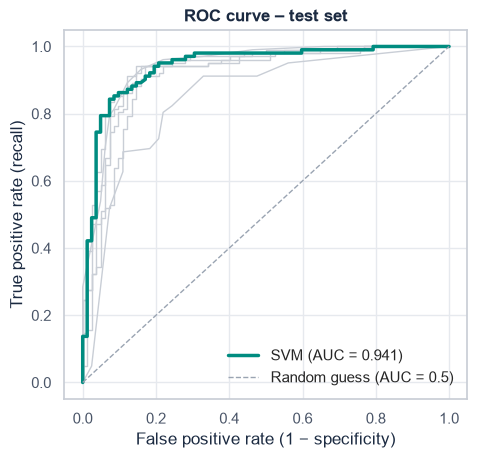

In [18]:
from sklearn.metrics import roc_curve, roc_auc_score
fig, ax = plt.subplots(figsize=(5.2, 4.8))
for name, prob in holdout_prob.items():
    if name != best_name:
        fpr, tpr, _ = roc_curve(y_test, prob)
        ax.plot(fpr, tpr, color="#C9CED6", lw=1)
fpr, tpr, _ = roc_curve(y_test, best_prob)
ax.plot(fpr, tpr, color=C.TEAL, lw=2.5, label=f"{best_name} (AUC = {roc_auc_score(y_test, best_prob):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#9AA4B2", lw=1, label="Random guess (AUC = 0.5)")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve – test set")
ax.legend(loc="lower right", frameon=False)
plots.save_fig(fig, "07_roc_curve")
plt.show()

## 10. Bootstrapping a 95% confidence interval for recall
The test set has only 184 patients, so the recall we measured is uncertain. **Bootstrapping**: draw 184 patients from the test set
*with replacement* (some appear twice, some not at all), recompute recall, and repeat 2,000 times. The middle 95% of those recalls
is the **95% bootstrap confidence interval**.

Recall on test set: 0.902   95% bootstrap CI: [0.837, 0.957]


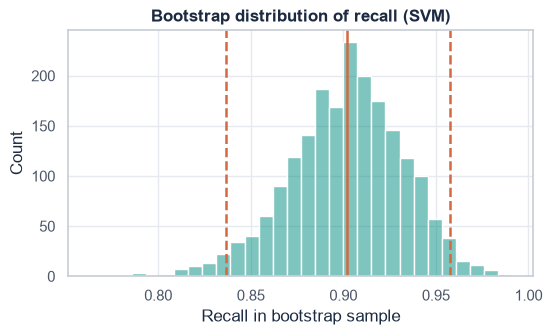

In [19]:
ci = M.bootstrap_ci(y_test, best_pred, n_boot=2000)
print(f"Recall on test set: {ci['estimate']:.3f}   95% bootstrap CI: [{ci['lower']:.3f}, {ci['upper']:.3f}]")

fig, ax = plt.subplots(figsize=(6, 3.2))
sns.histplot(ci["scores"], bins=30, color=C.TEAL, alpha=0.5, ax=ax)
for v, ls in [(ci["lower"], "--"), (ci["upper"], "--"), (ci["estimate"], "-")]:
    ax.axvline(v, color=C.CLASS_COLORS[1], ls=ls, lw=1.8)
ax.set_xlabel("Recall in bootstrap sample")
ax.set_title(f"Bootstrap distribution of recall ({best_name})")
plots.save_fig(fig, "07_bootstrap_recall")
plt.show()

## 11. Which features matter most? (permutation importance)
**Permutation importance:** shuffle one feature's column in the test set (destroying its information) and measure how much the
ROC-AUC drops. A big drop = the model relies heavily on that feature. It works for any model and on the original 11 features.

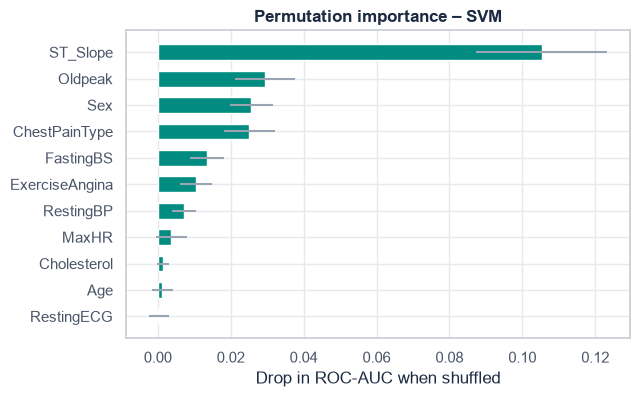

,feature,importance,std
10,ST_Slope,0.105,0.018
4,Oldpeak,0.029,0.008
5,Sex,0.026,0.006
6,ChestPainType,0.025,0.007
7,FastingBS,0.013,0.005
9,ExerciseAngina,0.011,0.004
1,RestingBP,0.007,0.003
3,MaxHR,0.004,0.004
2,Cholesterol,0.001,0.002
0,Age,0.001,0.003


In [20]:
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=C.RANDOM_STATE)
imp = pd.DataFrame({"feature": X.columns, "importance": perm.importances_mean, "std": perm.importances_std}).sort_values("importance")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(imp["feature"], imp["importance"], xerr=imp["std"], color=C.TEAL, height=0.6, error_kw={"ecolor": "#9AA4B2"})
ax.set_xlabel("Drop in ROC-AUC when shuffled")
ax.set_title(f"Permutation importance – {best_name}")
plots.save_fig(fig, "07_permutation_importance")
plt.show()
imp.sort_values("importance", ascending=False).round(4)

## 12. Save the final pipeline and a metrics file for the app
* `models/best_model.joblib` - the **complete fitted pipeline** (preprocessing + model). The app feeds it a raw patient row and gets a probability;
  it never retrains. We save the pipeline fitted on the 80% training split, so every test-set number shown in the app belongs exactly to this saved object.
* `models/metrics.json` - all validation results, the confusion matrix, ROC points, the bootstrap CI and feature importances.

In [21]:
C.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(best_pipe, C.MODEL_FILE)

def clean_std(v):
    return None if v is None or (isinstance(v, float) and np.isnan(v)) else float(v)

metrics = {
    "project": "CardioInsight",
    "random_state": C.RANDOM_STATE,
    "n_patients": int(len(df)), "n_features": int(X.shape[1]),
    "train_size": int(len(X_train)), "test_size": int(len(X_test)),
    "best_model": best_name,
    "selection_rule": "Highest (recall + F1) / 2 under stratified 10-fold cross-validation",
    "models": list(models),
    "strategies": strategies,
    "cv_results": [{**r, "mean": float(r["mean"]), "std": clean_std(r["std"])} for r in results.to_dict("records")],
    "ranking": ranking.reset_index().rename(columns={"index": "model"}).to_dict("records"),
    "holdout": {n: {k: float(v) for k, v in h.items()} for n, h in holdout.items()},
    "roc_all": {n: {**M.roc_points(y_test, p), "auc": float(roc_auc_score(y_test, p))} for n, p in holdout_prob.items()},
    "best": {
        "holdout_metrics": {k: float(v) for k, v in bm.items()},
        "confusion_matrix": [[bm["tn"], bm["fp"]], [bm["fn"], bm["tp"]]],
        "recall_ci": {k: ci[k] for k in ["estimate", "lower", "upper"]},
        "permutation_importance": imp.sort_values("importance", ascending=False)[["feature", "importance", "std"]].to_dict("records"),
    },
    "tuning": tuning,
    "reference_profile": {k: (v.item() if hasattr(v, "item") else v) for k, v in M.reference_profile(df).items()},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
M.save_json(metrics, C.METRICS_FILE)
print("Saved:", C.MODEL_FILE.relative_to(C.ROOT), "and", C.METRICS_FILE.relative_to(C.ROOT))

Saved: models\best_model.joblib and models\metrics.json


Sanity check: reload the saved pipeline and predict one raw patient row (exactly what the app will do).

In [22]:
reloaded = joblib.load(C.MODEL_FILE)
sample = X_test.iloc[[0]]
display(sample)
print(f"Predicted probability of heart disease: {reloaded.predict_proba(sample)[0, 1]:.3f}  (true label: {y_test.iloc[0]})")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], best_prob)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex,ChestPainType,FastingBS,RestingECG,ExerciseAngina,ST_Slope
356,46,115,0,113,1.500,M,ASY,0,Normal,Y,Flat


Predicted probability of heart disease: 0.935  (true label: 1)


## Key Findings
* **All seven models perform similarly** under 10-fold CV (accuracy 0.83–0.87, ROC-AUC 0.90–0.93); the single Decision Tree is clearly the weakest.
* The **hold-out split is optimistic/noisy**: e.g. Random Forest recall is 0.931 on the hold-out split but 0.906 under 10-fold CV. Cross-validation gives more trustworthy numbers, and the ± std shows the fold-to-fold variation (≈ 0.03–0.05).
* **5-fold, 10-fold and LOOCV agree closely** for Logistic Regression (recall 0.888 / 0.890 / 0.882) and Naive Bayes (0.864 / 0.866 / 0.864), so 10-fold CV is enough - LOOCV costs 918 fits for no real gain.
* **Selected model: SVM (RBF kernel)** - highest 10-fold recall (0.910) and F1 (0.885), selection score 0.897, just ahead of Random Forest (0.895) and XGBoost (0.891).
* **GridSearchCV** (24 combinations of C and γ, 5-fold CV on the training split) found C = 0.5, γ = 0.1 with a score only ≈ 0.006 above the defaults - smaller than the fold-to-fold std, so the **default settings were kept** to avoid over-fitting the validation folds.
* Classes are only mildly imbalanced (1.24 : 1), so **SMOTE was explained and visualised but not applied** - over-sampling the smaller (healthy) class would even work against recall.
* On the untouched test set the SVM catches **92 of 102 sick patients (recall 0.902, 95% bootstrap CI 0.837–0.957)** with ROC-AUC 0.941. It makes **10 Type II errors (missed patients)** and **14 Type I errors (false alarms)**.
* The bootstrap CI is wide (≈ ±6 points) because the test set is small - a single recall number should never be reported without its uncertainty.
* **ST_Slope** is by far the most important feature, followed by Oldpeak, Sex and ChestPainType; Cholesterol, Age and RestingECG add almost nothing once the other features are known.
* The full pipeline is saved to `models/best_model.joblib` and all metrics to `models/metrics.json` for the app.